In [2]:
import numpy as np
import matplotlib.pyplot as plt

stack_aia = np.load("phi_N_stack_aia.npy")
stack_vp = np.load("phi_N_stack_vp.npy")
T = np.load("T_good.npy")
wvl = np.linspace(500, 700, 41)

In [3]:
from ridb import RIDB
ridb = RIDB()

# Film model on any wavelength grid: T (glass side, normalized to bare glass) and R (film side, absolute)
silver = ridb.get_material("Ag_Rakic")


def interface(n_a, n_b):
    return (n_a - n_b)/(n_a + n_b), 2*n_a/(n_a + n_b)


def airy(wl, r_a, t_a, r_b, t_b, n, d):
    """Airy sum for a layer of index n, thickness d between interfaces a (entry) and b (exit)."""
    ph = np.exp(2j*np.pi/wl*n*d)
    den = 1 + r_a*r_b*ph**2
    return (r_a + r_b*ph**2)/den, t_a*t_b*ph/den


def film_rt(wl, n_si, d, d_ox):
    """Glass/Si/SiO2/air film on a thick substrate: T/T_glass seen from the glass side, R from the film side."""
    n_g = glass.n(wl)
    n_ox, n_a = n_g, np.ones_like(n_g)
    # from the glass side: SiO2 layer seen from Si, then Si layer seen from glass
    r_b, t_b = airy(wl, *interface(n_si, n_ox), *interface(n_ox, n_a), n_ox, d_ox)
    r_gs, t_gs = airy(wl, *interface(n_g, n_si), r_b, t_b, n_si, d)
    # from the air side: Si layer seen from SiO2, then SiO2 layer seen from air
    r_b, _ = airy(wl, *interface(n_ox, n_si), *interface(n_si, n_g), n_si, d)
    r_as, _ = airy(wl, *interface(n_a, n_ox), r_b, 1.0, n_ox, d_ox)
    # thick substrate: incoherent sum of back-face reflections
    R_back = np.abs(interface(n_g, n_a)[0])**2
    T_back = 1 - R_back
    T_f = n_a.real/n_g.real*np.abs(t_gs)**2          # film transmittance (same in both directions)
    R_fg, R_fa = np.abs(r_gs)**2, np.abs(r_as)**2    # film reflectance from glass / air side
    T = T_back*T_f/(1 - R_back*R_fg)
    R = R_fa + T_f**2*R_back/(1 - R_back*R_fg)
    T_glass = T_back**2/(1 - R_back**2)
    return T/T_glass, R

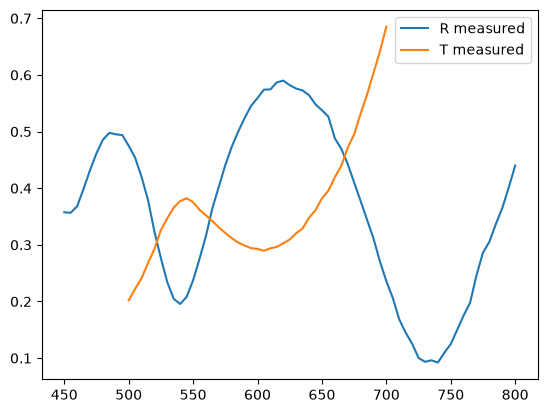

In [6]:
# Measured reflection (film side, divided by a protected-silver mirror) -> absolute R
wvl_R = np.linspace(400, 800, 81)
R_meas = np.load("Reflection_EML130824_1_Si_400_800.npy")*np.abs(interface(1, silver.n(wvl_R))[0])**2
keep = wvl_R >= 450
wvl_R, R_meas = wvl_R[keep], R_meas[keep]

plt.plot(wvl_R, R_meas, label="R measured")
plt.plot(wvl, T, label="T measured")
plt.legend()
plt.show()

In [7]:
def centered(p):
    """Wrapped phase -> zero-mean real map around its circular mean (sign flip -> negation)."""
    z = np.exp(1j * p)
    x = np.angle(z * np.conj(z.mean()))
    return x - x.mean()

def _peak_offset(cm, c0, cp):
    d = cm - 2 * c0 + cp
    return 0.0 if d == 0 else 0.5 * (cm - cp) / d

def signed_shift(ref, img, max_shift=40):
    """Sub-pixel (dy, dx) rolling img onto ref, and the signed normalized correlation r at that shift.
    r < 0 means img has the opposite phase sign."""
    c = np.fft.ifft2(np.fft.fft2(ref) * np.fft.fft2(img).conj()).real
    c = np.fft.fftshift(c) / (np.linalg.norm(ref) * np.linalg.norm(img))
    H, W = c.shape; cy, cx = H // 2 - max_shift, W // 2 - max_shift
    win = np.abs(c[cy:cy + 2 * max_shift + 1, cx:cx + 2 * max_shift + 1])
    iy, ix = np.unravel_index(win.argmax(), win.shape)
    py, px = cy + iy, cx + ix
    dy = iy - max_shift + _peak_offset(*np.abs(c[py - 1:py + 2, px]))
    dx = ix - max_shift + _peak_offset(*np.abs(c[py, px - 1:px + 2]))
    return dy, dx, c[py, px]

def register_wavelengths(ref_stack, roi, max_shift=40):
    """Chain neighbouring wavelengths of ref_stack (wvl, Y, X): cumulative sign and shift relative to wvl 0."""
    X = [centered(p[roi]) for p in ref_stack]
    signs, shifts, corr = [1], [np.zeros(2)], [1.0]
    for k in range(1, len(X)):
        dy, dx, r = signed_shift(X[k - 1], X[k], max_shift)
        signs.append(signs[-1] * int(np.sign(r)))
        shifts.append(shifts[-1] + (dy, dx))
        corr.append(r)
    return np.array(signs), np.array(shifts), np.array(corr)

def signs_vs_reference(stack, ref_stack, roi):
    """Sign of every (N, wvl) map relative to ref_stack at the same wavelength (zero shift)."""
    r = np.empty(stack.shape[:2])
    for w in range(stack.shape[1]):
        x_ref = centered(ref_stack[w][roi])
        for n in range(stack.shape[0]):
            x = centered(stack[n, w][roi])
            r[n, w] = (x * x_ref).sum() / np.sqrt((x**2).sum() * (x_ref**2).sum())
    return np.sign(r).astype(int), r

def apply_registration(stack, signs, shifts):
    """Flip signs (N, wvl), roll each wavelength by integer shifts (wvl, 2), crop to the common valid window."""
    N, L, H, W = stack.shape
    y0, x0 = shifts.max(0).clip(min=0)
    y1, x1 = np.array([H, W]) + shifts.min(0).clip(max=0)
    out = np.empty((N, L, y1 - y0, x1 - x0), stack.dtype)
    for w, (dy, dx) in enumerate(shifts):
        out[:, w] = stack[:, w, y0 - dy:y1 - dy, x0 - dx:x1 - dx] * signs[:, w, None, None].astype(stack.dtype)
    return out

In [8]:
roi = (slice(250, 1250), slice(1000, 2000))
ref = stack_aia[-1]                                   # largest N of AIA: reference for both stacks

s_wvl, shifts_f, r_wvl = register_wavelengths(ref, roi)
shifts = np.rint(shifts_f).astype(int)

s_aia, r_aia = signs_vs_reference(stack_aia, ref, roi)
s_vp, r_vp = signs_vs_reference(stack_vp, ref, roi)
signs_aia = s_aia * s_wvl[None]
signs_vp = s_vp * s_wvl[None]

print("min |r| neighbour wvl:", np.abs(r_wvl[1:]).min().round(3))
print("min |r| vs ref  AIA:", np.abs(r_aia).min().round(3), " VP:", np.abs(r_vp).min().round(3))

stack_aia_reg = apply_registration(stack_aia, signs_aia, shifts)
stack_vp_reg = apply_registration(stack_vp, signs_vp, shifts)
print(stack_aia_reg.shape)

min |r| neighbour wvl: 0.779
min |r| vs ref  AIA: 0.918  VP: 0.011
(11, 41, 2183, 3288)


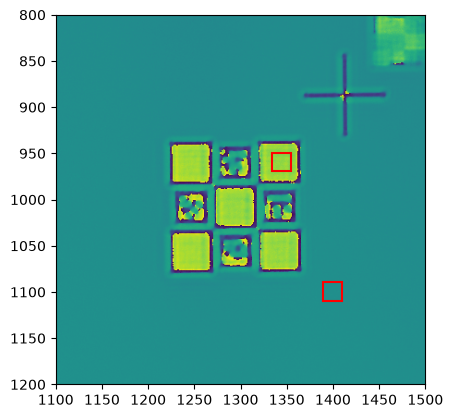

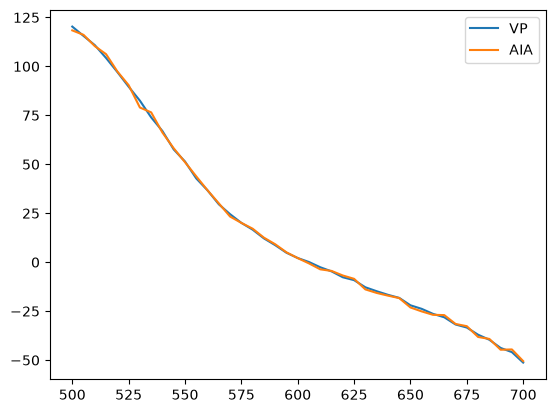

In [57]:
from matplotlib.patches import Rectangle

side = 20

xc1 = 1345
yc1 = 960
side1 = 20

xc2 = 1400
yc2 = 1100
side2 = side

squares = [(xc1 - side1//2, yc1 - side1//2, side1), (xc2 - side2//2, yc2 - side2//2, side2)]   # (x, y, side) in pixels

fig, ax = plt.subplots()
ax.imshow(stack_vp_reg[10, 0])
for x, y, s in squares:
    ax.add_patch(Rectangle((x - 0.5, y - 0.5), s, s, fill=False, edgecolor="red", linewidth=1.5))
ax.set_xlim(1100, 1500)
ax.set_ylim(1200, 800)   # imshow has y pointing down
plt.show()

# Average over
x1, y1, s1 = squares[0]
x2, y2, s2 = squares[1]
stack_vp_res = stack_vp_reg[:,:,y1:y1+s1,x1:x1+s1].mean(axis=(-2, -1)) - stack_vp_reg[:,:,y2:y2+s2,x2:x2+s2].mean(axis=(-2, -1))
stack_aia_res = stack_aia_reg[:,:,y1:y1+s1,x1:x1+s1].mean(axis=(-2, -1)) - stack_aia_reg[:,:,y2:y2+s2,x2:x2+s2].mean(axis=(-2, -1))
plt.figure()
plt.plot(wvl, stack_vp_res[5]*180/np.pi, label="VP")
plt.plot(wvl, stack_aia_res[5]*180/np.pi, label="AIA")
plt.legend()
plt.show()

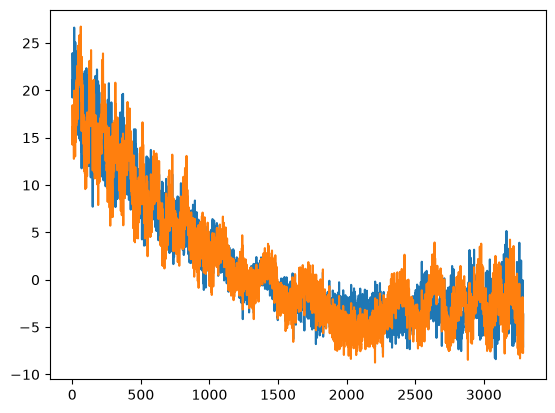

In [47]:
plt.plot(stack_vp_reg[10, 0, 1250]*180/np.pi)
plt.plot(stack_aia_reg[10, 0, 1250]*180/np.pi)

(-0.5, 0.5)

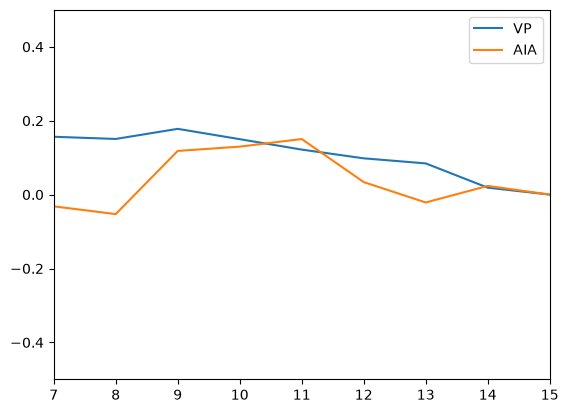

In [6]:
n = np.arange(5, 16)
plt.figure()
plt.plot(n, (stack_vp_res - stack_vp_res[-1,:]).mean(axis=-1)*180/np.pi, label="VP")
plt.plot(n, (stack_aia_res - stack_aia_res[-1,:]).mean(axis=-1)*180/np.pi, label="AIA")
plt.legend()
plt.xlim(7, 15)
plt.ylim([-0.5, 0.5])

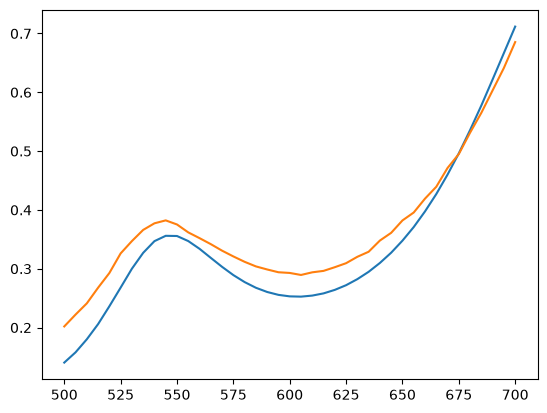

In [15]:
# Theoretical data
aSi_150 = ridb.get_material("aSi_LPCVD_150nm_110824")
aSi_200 = ridb.get_material("aSi_LPCVD_200nm_110824")
glass  = ridb.get_material("Fused_Silica_Franta")

n_si_150 = aSi_150.n(wvl)
n_si_200 = aSi_200.n(wvl)
n_glass = glass.n(wvl)
n_air = np.ones_like(n_glass)

n_si = n_si_200
d = 185

# Fresnel formulas 

t_back = 2*n_air/(n_air+n_glass)
T_back = n_glass.real/n_air.real *np.abs(t_back)**2

r_back = (n_air - n_glass)/(n_air + n_glass)
R_back = np.abs(r_back)**2

r12_si = (n_glass - n_si)/(n_glass + n_si)
r23_si = (n_si - n_air)/(n_si + n_air)
t12_si = 2*n_glass/(n_glass + n_si)
t23_si = 2*n_si/(n_si + n_air)
beta = 2*np.pi/wvl*n_si*d

t_si = t12_si*t23_si*np.exp(1j*beta)/(1 + r12_si*r23_si*np.exp(2j*beta))
r_si = (r12_si + r23_si*np.exp(2j*beta))/(1 + r12_si*r23_si*np.exp(2j*beta))

T_film = n_air.real/n_glass.real*np.abs(t_si)**2
T_si = T_film*T_back/(1 - R_back*np.abs(r_si)**2)

T_ref = T_back**2/(1 - R_back**2)

plt.plot(wvl, T_si/T_ref)
plt.plot(wvl ,T)

In [17]:
# Tauc-Lorentz model, film response, LM solver
HC = 1239.84193  # eV*nm


def tauc_lorentz(wvl, A, E0, C, Eg, eps_inf, E_max=100.0, n_grid=20000):
    """Complex refractive index n + ik of a Tauc-Lorentz oscillator (Jellison-Modine)."""
    E = HC/np.asarray(wvl, float)

    def eps2(x):
        x = np.asarray(x, float)
        val = A*E0*C*(x - Eg)**2/((x**2 - E0**2)**2 + C**2*x**2)/x
        return np.where(x > Eg, val, 0.0)

    # eps1 by Kramers-Kronig; subtracting E*eps2(E) removes the pole at xi = E
    xi = Eg + (E_max - Eg)*np.linspace(0, 1, n_grid)**2
    e2 = eps2(E)
    with np.errstate(divide="ignore", invalid="ignore"):
        f = (xi*eps2(xi) - (E*e2)[:, None])/(xi**2 - E[:, None]**2)
    f = np.where(np.isfinite(f), f, 0.0)
    pv = np.trapezoid(f, xi, axis=1)
    pv += e2/2*np.log(np.abs((E_max - E)*(Eg + E)/((E_max + E)*(Eg - E))))
    eps = eps_inf + 2/np.pi*pv + 1j*e2
    return np.sqrt(eps)


def layer(r_a, t_a, r_b, t_b, n, d):
    """Airy sum for a layer of index n, thickness d between interfaces a (entry) and b (exit)."""
    ph = np.exp(2j*np.pi/wvl*n*d)
    den = 1 + r_a*r_b*ph**2
    return (r_a + r_b*ph**2)/den, t_a*t_b*ph/den


def film(n_si, d, d_ox=0.0, n_ox=None):
    """Si film with SiO2 on top (glass -> Si -> SiO2 -> air): t_si and T normalized to bare glass."""
    n_ox = n_glass if n_ox is None else n_ox
    # SiO2 layer seen from Si, then Si layer seen from glass
    r23, t23 = layer((n_si - n_ox)/(n_si + n_ox), 2*n_si/(n_si + n_ox),
                     (n_ox - n_air)/(n_ox + n_air), 2*n_ox/(n_ox + n_air), n_ox, d_ox)
    r_si, t_si = layer((n_glass - n_si)/(n_glass + n_si), 2*n_glass/(n_glass + n_si),
                       r23, t23, n_si, d)
    T_film = n_air.real/n_glass.real*np.abs(t_si)**2
    T_si = T_film*T_back/(1 - R_back*np.abs(r_si)**2)
    return t_si, T_si/T_ref


def levenberg_marquardt(residual, p0, lo, hi, iters=200, tol=1e-10):
    """Bounded least squares; parameters are scaled by |p0| internally."""
    p0 = np.asarray(p0, float)
    s = np.where(p0 != 0, np.abs(p0), 1.0)
    q, lo, hi = p0/s, np.asarray(lo)/s, np.asarray(hi)/s
    res = lambda q: residual(q*s)
    r = res(q)
    cost, lam = r @ r, 1.0
    for _ in range(iters):
        h = 1e-6*np.maximum(np.abs(q), 1)
        J = np.stack([(res(q + h[i]*np.eye(len(q))[i]) - r)/h[i] for i in range(len(q))], axis=1)
        JTJ, g = J.T @ J, J.T @ r
        # freeze parameters held at a bound by the gradient
        free = ~(((q <= lo) & (g > 0)) | ((q >= hi) & (g < 0)))
        A_ = JTJ[np.ix_(free, free)]
        while True:
            step = np.zeros_like(q)
            step[free] = np.linalg.solve(A_ + lam*np.diag(np.diag(A_) + 1e-12), g[free])
            q_new = np.clip(q - step, lo, hi)
            r_new = res(q_new)
            if r_new @ r_new < cost:
                done = cost - r_new @ r_new < tol*cost
                q, r, cost, lam = q_new, r_new, r_new @ r_new, lam/3
                break
            lam *= 4
            if lam > 1e10:
                return q*s, cost
        if done:
            break
    return q*s, cost

{'A': np.float64(115.7113), 'E0': np.float64(4.0586), 'C': np.float64(0.9018), 'Eg': np.float64(1.3265), 'eps_inf': np.float64(1.1496)}


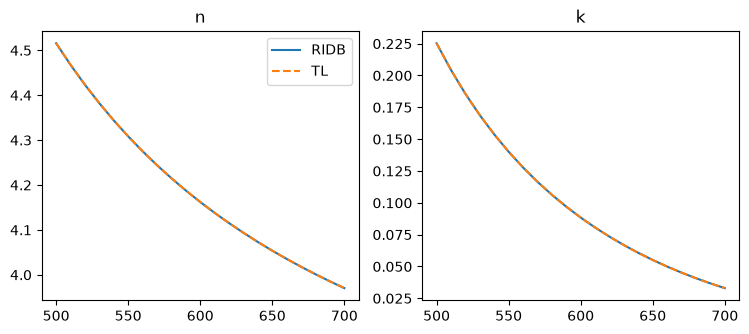

In [18]:
# Fit Tauc-Lorentz to the old (RIDB) dispersion
names = ["A", "E0", "C", "Eg", "eps_inf"]
p0 = [150.0, 3.6, 2.4, 1.2, 1.0]
lo = [1.0, 1.5, 0.1, 0.5, 0.0]
hi = [1000.0, 10.0, 10.0, 2.5, 10.0]

eps_old = n_si_200**2
def res_old(p):
    eps = tauc_lorentz(wvl, *p)**2
    return np.concatenate([(eps - eps_old).real, (eps - eps_old).imag])

p_old, _ = levenberg_marquardt(res_old, p0, lo, hi)
print(dict(zip(names, np.round(p_old, 4))))

n_tl_old = tauc_lorentz(wvl, *p_old)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(wvl, n_si_200.real, label="RIDB"); ax[0].plot(wvl, n_tl_old.real, "--", label="TL"); ax[0].set_title("n"); ax[0].legend()
ax[1].plot(wvl, n_si_200.imag); ax[1].plot(wvl, n_tl_old.imag, "--"); ax[1].set_title("k")
plt.show()

{'A': np.float64(102.9963), 'E0': np.float64(4.1559), 'C': np.float64(0.888), 'Eg': np.float64(1.1724), 'eps_inf': np.float64(0.0)} d = 194.08 d_ox = 0.0 rms T = 0.05039030928128386 rms R = 0.00994072522662072


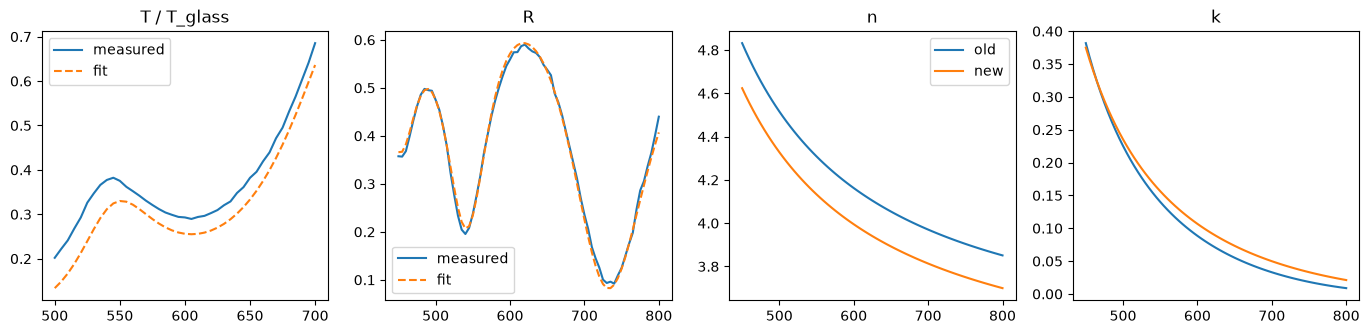

In [105]:
# Joint fit of T and R: Tauc-Lorentz and/or d_ox, d (unfitted TL stays at the old fit)
T_data = T    # transmission to fit: T_reg_res (intensities) or T_b_res (|b|^2, run the comparison cell first)
use_T = False          # include transmission in the fit
use_R = True         # include reflection in the fit
fit_tl = True
fit_d = True
fit_d_ox = False
d0 = 197
d_ox0 = 0
tie_d_to_ox = False   # d = d_init - SI_PER_OX*d_ox (Si consumed by oxidation); replaces fit_d
d_init = 197
SI_PER_OX = 0.44
assert not (tie_d_to_ox and fit_d), "tie_d_to_ox replaces fit_d: set fit_d = False"
assert fit_d_ox or not tie_d_to_ox, "tie_d_to_ox needs fit_d_ox = True, otherwise d stays at d_init"

def unpack(p):
    i = 5*fit_tl
    tl = p[:5] if fit_tl else p_old
    d_ox = p[i] if fit_d_ox else d_ox0
    d = d_init - SI_PER_OX*d_ox if tie_d_to_ox else (p[i + fit_d_ox] if fit_d else d0)
    return tl, d_ox, d

def model_rt(p):
    tl, dox, dd = unpack(p)
    return (film_rt(wvl, tauc_lorentz(wvl, *tl), dd, dox)[0],
            film_rt(wvl_R, tauc_lorentz(wvl_R, *tl), dd, dox)[1])

def res_rt(p):
    T, R = model_rt(p)
    return np.concatenate([(T - T_data)[:len(wvl)*use_T], (R - R_meas)[:len(wvl_R)*use_R]])

p_start = np.r_[p_old if fit_tl else [], [d_ox0]*fit_d_ox, [d0]*fit_d]
p_rt, cost = levenberg_marquardt(res_rt, p_start,
                                 lo*fit_tl + [0]*fit_d_ox + [d0 - 50]*fit_d,
                                 hi*fit_tl + [150]*fit_d_ox + [d0 + 50]*fit_d, iters=1000)
tl_rt, d_ox_rt, d_rt = unpack(p_rt)
T_rt, R_rt = model_rt(p_rt)
print(dict(zip(names, np.round(tl_rt, 4))), "d =", round(float(d_rt), 2), "d_ox =", round(float(d_ox_rt), 2),
      "rms T =", np.sqrt(np.mean((T_rt - T_data)**2)), "rms R =", np.sqrt(np.mean((R_rt - R_meas)**2)))

n_rt = tauc_lorentz(wvl_R, *tl_rt)
fig, ax = plt.subplots(1, 4, figsize=(17, 3.5))
ax[0].plot(wvl, T_data, label="measured"); ax[0].plot(wvl, T_rt, "--", label="fit"); ax[0].set_title("T / T_glass"); ax[0].legend()
ax[1].plot(wvl_R, R_meas, label="measured"); ax[1].plot(wvl_R, R_rt, "--", label="fit"); ax[1].set_title("R"); ax[1].legend()
ax[2].plot(wvl_R, tauc_lorentz(wvl_R, *p_old).real, label="old"); ax[2].plot(wvl_R, n_rt.real, label="new"); ax[2].set_title("n"); ax[2].legend()
ax[3].plot(wvl_R, tauc_lorentz(wvl_R, *p_old).imag); ax[3].plot(wvl_R, n_rt.imag); ax[3].set_title("k")
plt.show()

In [108]:
# Get updated phase results
def load_res(path):
    """Load a (wvl, H, W) phase stack, fix its sign per wavelength, register, and take Si - glass."""
    phi = np.load(path)
    s, r = signs_vs_reference(phi[None], ref, roi)          # sign vs the AIA reference, per wavelength
    phi = apply_registration(phi[None], s * s_wvl[None], shifts)[0]
    print(path, "min |r|:", np.abs(r).min().round(3))
    res = phi[:, y1:y1+s1, x1:x1+s1].mean(axis=(-2, -1)) - phi[:, y2:y2+s2, x2:x2+s2].mean(axis=(-2, -1))
    return phi, res

#phi_new_vp_n10_leak, phi_new_vp_n10_leak_res = load_res("phi_wvl_stack_vp_n10_leak.npy")
phi_new_vp_n10, phi_new_vp_n10_res = load_res("phi_wvl_stack_vp_n10.npy")

phi_wvl_stack_vp_n10.npy min |r|: 0.882


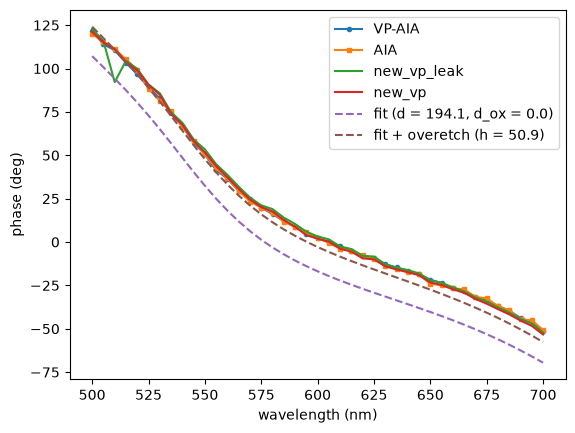

In [110]:
# Measured phase vs model: Si patch relative to the bare glass next to it
sign = 1   # +1 if the measured phase follows exp(+ikz); -1 for the opposite convention
N_idx = 10  # index into the N axis of the phase stacks
step = 245 # measured patch height above the etched glass, nm; overetch h = step - d - d_ox

def film_t(wl, n_si, d, d_ox, h=0.0):
    """Field transmission glass -> Si -> SiO2 -> air on a glass pedestal of height h,
    relative to the etched bare glass with air over h + d + d_ox."""
    n_g = glass.n(wl)
    n_ox, n_a = n_g, np.ones_like(n_g)
    r_b, t_b = airy(wl, *interface(n_si, n_ox), *interface(n_ox, n_a), n_ox, d_ox)
    t = airy(wl, *interface(n_g, n_si), r_b, t_b, n_si, d)[1]
    return t*np.exp(2j*np.pi/wl*(n_g - 1)*h)/(interface(n_g, n_a)[1]*np.exp(2j*np.pi/wl*(d + d_ox)))

wrap = lambda x: np.angle(np.exp(1j*x), deg=True)
models = {f"fit (d = {d_rt:.1f}, d_ox = {d_ox_rt:.1f})": (tauc_lorentz(wvl, *tl_rt), d_rt, d_ox_rt, 0),
          f"fit + overetch (h = {step - d_rt - d_ox_rt:.1f})": (tauc_lorentz(wvl, *tl_rt), d_rt, d_ox_rt, step - d_rt - d_ox_rt)}

plt.figure()
plt.plot(wvl, wrap(stack_vp_res[N_idx]), "o-", ms=3, label="VP-AIA")
plt.plot(wvl, wrap(stack_aia_res[N_idx]), "s-", ms=3, label="AIA")
plt.plot(wvl, wrap(phi_new_vp_n10_leak_res), label="new_vp_leak")
plt.plot(wvl, wrap(phi_new_vp_n10_res), label="new_vp")
for label, (n, dd, dox, h) in models.items():
    plt.plot(wvl, wrap(sign*np.angle(film_t(wvl, n, dd, dox, h))), "--", label=label)
plt.xlabel("wavelength (nm)"); plt.ylabel("phase (deg)")
plt.legend()
plt.show()

In [97]:
print(np.sqrt(np.mean((wrap(stack_vp_res[N_idx]) - wrap(sign*np.angle(film_t(wvl, n, dd, dox, h))))**2)))

9.726323479666963


In [107]:
r = wrap(stack_vp_res[N_idx]) - wrap(sign*np.angle(film_t(wvl, n, dd, dox, h)))
print("mean", r.mean(), "rms", np.sqrt(np.mean(r**2)), "spread", r.std())

mean 4.125231424733394 rms 4.9805241701966505 spread 2.790714371322354


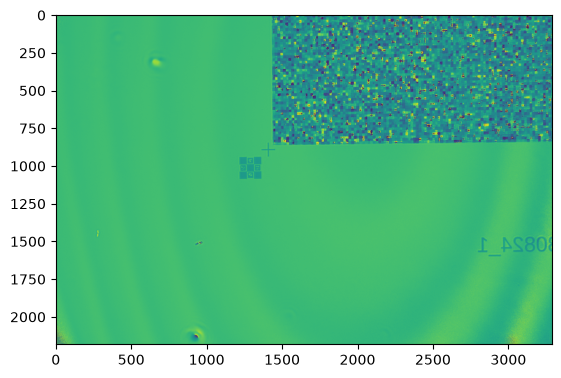

In [ ]:
plt.imshow(phi_new_vp_n10[-1])


h free: h = 79.4, step = 278.8: rms = 2.78 deg
h = 45.6 (step 245), offset = 9.66 deg: rms = 1.93 deg
both free: h = 0.0, step = 199.4, offset = 22.34 deg: rms = 1.21 deg


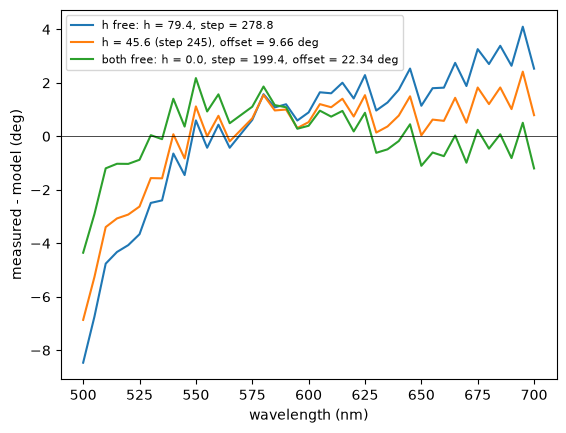

In [34]:
# Remaining bias: extra glass path (~1/wvl) vs constant phase offset, on the VP-AIA phase
meas = stack_vp_res[N_idx]
n_fit = tauc_lorentz(wvl, *tl_rt)
model = lambda h: sign*np.angle(film_t(wvl, n_fit, d_rt, d_ox_rt, h))
resid = lambda x: np.angle(np.exp(1j*x))   # wrapped residual, rad
h_meas = step - d_rt - d_ox_rt

fits = {}
# h free, no offset
p, _ = levenberg_marquardt(lambda p: resid(meas - model(p[0])), [h_meas], [0], [300])
fits[f"h free: h = {p[0]:.1f}, step = {p[0] + d_rt + d_ox_rt:.1f}"] = model(p[0])
# h from the measured step, constant offset free
c = np.angle(np.exp(1j*(meas - model(h_meas))).mean())
fits[f"h = {h_meas:.1f} (step {step}), offset = {np.degrees(c):.2f} deg"] = model(h_meas) + c
# h and offset both free
p, _ = levenberg_marquardt(lambda p: resid(meas - model(p[0]) - p[1]), [h_meas, 0.0], [0, -np.pi], [300, np.pi])
fits[f"both free: h = {p[0]:.1f}, step = {p[0] + d_rt + d_ox_rt:.1f}, offset = {np.degrees(p[1]):.2f} deg"] = model(p[0]) + p[1]

plt.figure()
for label, m in fits.items():
    r = np.degrees(resid(meas - m))
    print(f"{label}: rms = {np.sqrt(np.mean(r**2)):.2f} deg")
    plt.plot(wvl, r, label=label)
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("wavelength (nm)"); plt.ylabel("measured - model (deg)")
plt.legend(fontsize=8)
plt.show()